In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\sandr\Downloads\luminar\ncr_ride_bookings.csv")

In [5]:
# Are there missing values in each column?
print(df.isnull().sum())

Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64


In [6]:
# What is the total number of missing values?
print(df.isnull().sum().sum())

1123500


In [7]:
# Which columns contain missing values?
print(df.columns[df.isnull().any()])

Index(['Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer',
       'Reason for cancelling by Customer', 'Cancelled Rides by Driver',
       'Driver Cancellation Reason', 'Incomplete Rides',
       'Incomplete Rides Reason', 'Booking Value', 'Ride Distance',
       'Driver Ratings', 'Customer Rating', 'Payment Method'],
      dtype='str')


In [8]:

# Which columns have no missing values?
print(df.columns[df.notnull().all()])

Index(['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID',
       'Vehicle Type', 'Pickup Location', 'Drop Location'],
      dtype='str')


In [9]:

# Which columns contain the highest number of missing values?
print(df.isnull().sum().sort_values(ascending=False))

Incomplete Rides Reason              141000
Incomplete Rides                     141000
Reason for cancelling by Customer    139500
Cancelled Rides by Customer          139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Driver Ratings                        57000
Customer Rating                       57000
Avg CTAT                              48000
Ride Distance                         48000
Booking Value                         48000
Payment Method                        48000
Avg VTAT                              10500
Customer ID                               0
Booking Status                            0
Booking ID                                0
Time                                      0
Date                                      0
Pickup Location                           0
Drop Location                             0
Vehicle Type                              0
dtype: int64


In [ ]:
# Are there duplicate rows?
print(df.duplicated().sum())

In [ ]:
# How many rows remain after removing exact duplicates temporarily?
print(df.drop_duplicates().shape)

In [11]:
# Are there duplicate Booking IDs?
print(df["Booking ID"].duplicated().sum())

1233


In [10]:
# Are there duplicate Customer IDs?
print(df["Customer ID"].duplicated().sum())

1212


In [12]:
# Are Date and Time stored in the correct data types?
print(df[["Date", "Time"]].dtypes)

Date    str
Time    str
dtype: object


In [13]:
# Are all dates valid?
dates = pd.to_datetime(df["Date"], errors="coerce")
print(dates.isna().sum())

0


In [14]:

# Are Booking Value and Ride Distance numeric?
print(df[["Booking Value", "Ride Distance"]].dtypes)

Booking Value    float64
Ride Distance    float64
dtype: object


In [15]:

# Can ride distances be converted to numeric without errors?
print(pd.to_numeric(
    df["Ride Distance"], errors="coerce"
).isna().sum())

48000


In [16]:
# Are there negative booking values?
print((df["Booking Value"] < 0).sum())

0


In [17]:
# Are there zero booking values?
print((df["Booking Value"] == 0).sum())

0


In [18]:
# Are vehicle arrival times negative?
print((df["Avg VTAT"] < 0).sum())

0


In [19]:

# Are there missing or unexpected payment methods?
print(df["Payment Method"].value_counts(dropna=False))

Payment Method
NaN            48000
UPI            45909
Cash           25367
Uber Wallet    12276
Credit Card    10209
Debit Card      8239
Name: count, dtype: int64


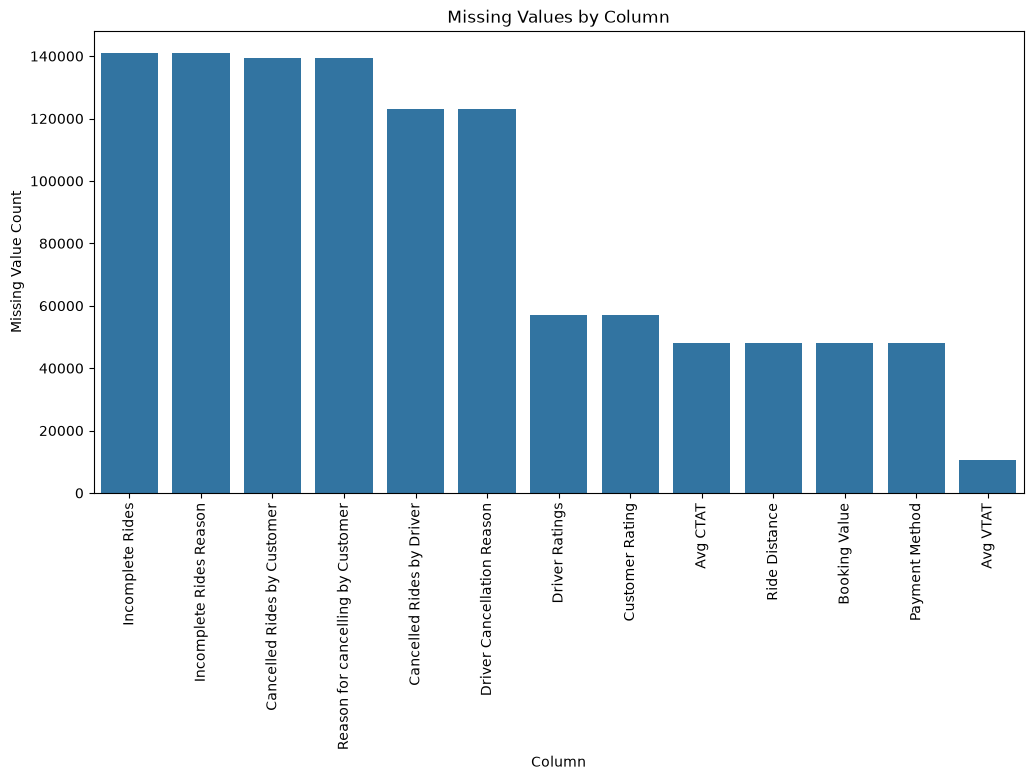

In [21]:
# Which columns have the most missing values?
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=missing.index, y=missing.values)
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=90)

plt.show()